In [1]:
import planet
from planet import data_filter
import requests
import os
import json
import datetime
import asyncio
import geopandas as gpd
import numpy as np
import shapely
import matplotlib.pyplot as plt

# grid area

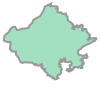

In [2]:
gdf=gpd.read_file('../../data/india-polygon.shp')
# gdf.head()
raja= gdf[gdf['st_nm']=='Rajasthan']
raja['geometry'].values[0]

<Axes: >

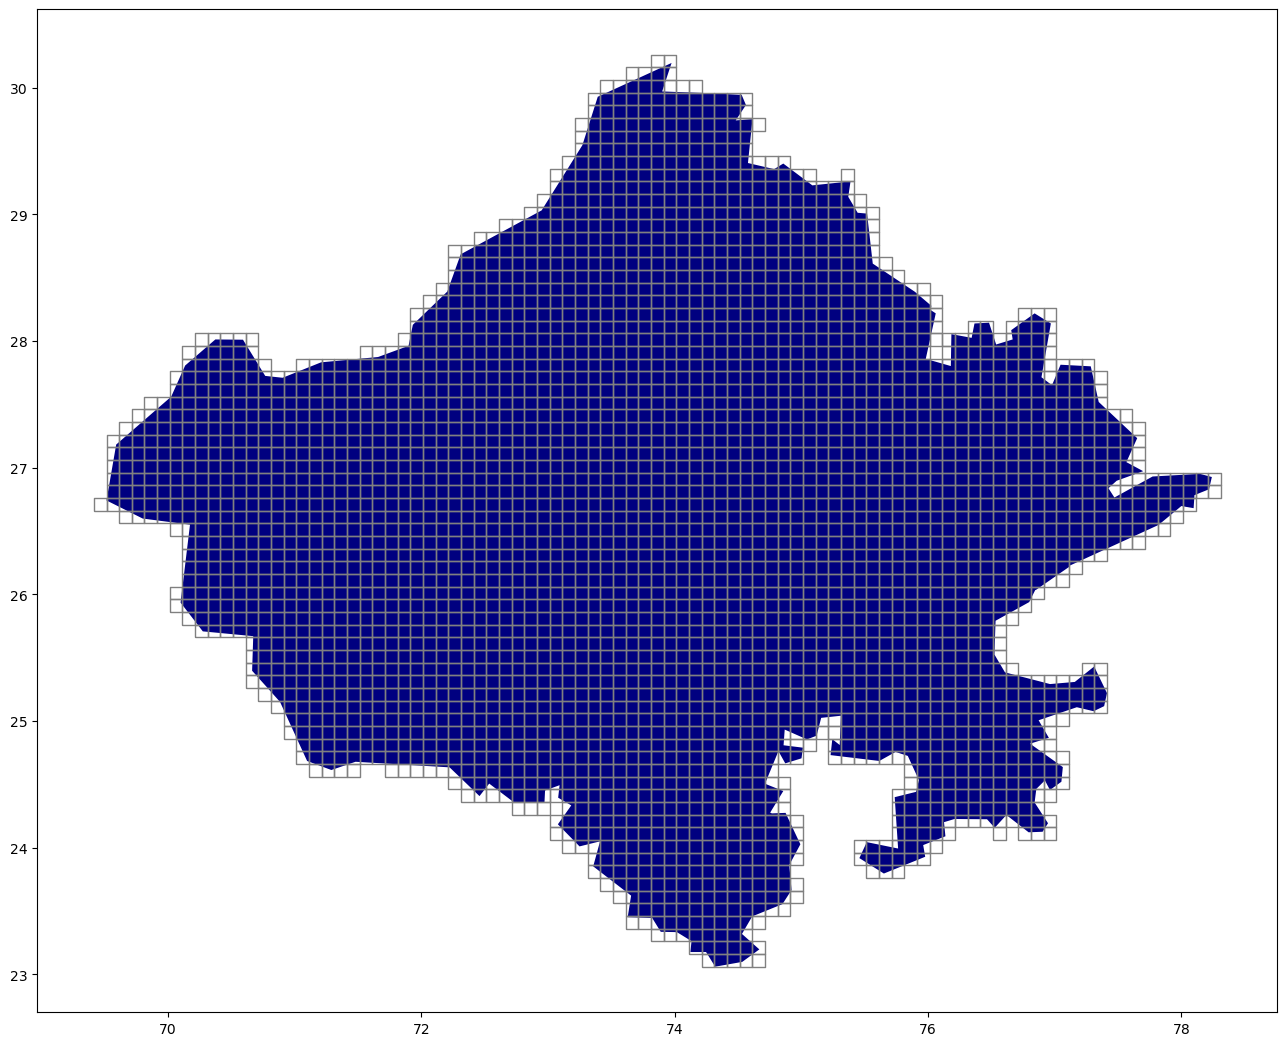

In [6]:

ax = raja.plot(markersize=.1, figsize=(16, 16), cmap='jet')

xmin, ymin, xmax, ymax= raja.total_bounds

## real cell dimensions
cell_width  = 0.1
cell_height = 0.1

grid_cells = []
for x0 in np.arange(xmin, xmax+cell_width, cell_width ):
    for y0 in np.arange(ymin, ymax+cell_height, cell_height):
        x1 = x0-cell_width
        y1 = y0+cell_height
        new_cell = shapely.geometry.box(x0, y0, x1, y1)
        if new_cell.intersects(raja['geometry'].values[0]):
            grid_cells.append(new_cell)
        else:
            pass
        
cell_df = gpd.GeoDataFrame(grid_cells, columns=['geometry'])
cell_df.plot(ax=ax,facecolor="none", edgecolor='grey')

In [7]:
cell_df['geojson'] = [shapely.to_geojson(cell_df['geometry'].values[d]) for d in cell_df.index]
cell_df

,geometry,geojson
0,"POLYGON ((69.41448 26.66099, 69.41448 26.76099...","{""type"":""Polygon"",""coordinates"":[[[69.41448095..."
1,"POLYGON ((69.51448 26.66099, 69.51448 26.76099...","{""type"":""Polygon"",""coordinates"":[[[69.51448095..."
2,"POLYGON ((69.51448 26.76099, 69.51448 26.86099...","{""type"":""Polygon"",""coordinates"":[[[69.51448095..."
3,"POLYGON ((69.51448 26.86099, 69.51448 26.96099...","{""type"":""Polygon"",""coordinates"":[[[69.51448095..."
4,"POLYGON ((69.51448 26.96099, 69.51448 27.06099...","{""type"":""Polygon"",""coordinates"":[[[69.51448095..."
...,...,...
3325,"POLYGON ((78.01448 26.86099, 78.01448 26.96099...","{""type"":""Polygon"",""coordinates"":[[[78.01448095..."
3326,"POLYGON ((78.11448 26.76099, 78.11448 26.86099...","{""type"":""Polygon"",""coordinates"":[[[78.11448095..."
3327,"POLYGON ((78.11448 26.86099, 78.11448 26.96099...","{""type"":""Polygon"",""coordinates"":[[[78.11448095..."
3328,"POLYGON ((78.21448 26.76099, 78.21448 26.86099...","{""type"":""Polygon"",""coordinates"":[[[78.21448095..."


# search for imagery

In [5]:
async def search(session, geometry, toi_start, toi_end, item_type):  
    # Initialize the Data API client so we can search for scenes:
    cl_data = session.client("data")


    # Create search filter based on the user's filter parameters:
    search_filter = data_filter.and_filter(
       [
           data_filter.date_range_filter("acquired", gte=toi_start, lte=toi_end),
           data_filter.geometry_filter(geometry),
       ]
    )


    # Search for filtered asset ids:
    # I set the limit to 0, to make sure all scenes are returned.

    ids = [i["id"] async for i in cl_data.search([item_type], search_filter, limit=0)]


    print(
       f"""{len(ids)} scenes were found. If this number seems too high,
               narrow down your search by using a shorter TOI range."""
    )

    return ids

In [6]:
# toi_start= datetime.datetime(2015,1,1)
# toi_end= datetime.datetime(2023,12,31)

# item_type = "SkySatScene"

# # with open('test_area.geojson') as f:
# #     geometry=json.load(f)
    

# # Setup the session
# session = planet.Session()
# heatmap=[]
# for i in cell_df.index:
#     print(f'{i}/{len(cell_df)}')
#     geometry=json.loads(cell_df['geojson'].values[i])
#     async with planet.Session() as sess:
#         ids = await search(sess, geometry, toi_start, toi_end, item_type)
#     heatmap+=[len(ids)]

# cell_df['heatmap']=heatmap

# cell_df.to_file('rajasthan_heatmap.shp')

cell_df.read_file('rajasthan_heatmap.shp')




445 scenes were found. If this number seems too high,
               narrow down your search by using a shorter TOI range.
273 scenes were found. If this number seems too high,
               narrow down your search by using a shorter TOI range.
114 scenes were found. If this number seems too high,
               narrow down your search by using a shorter TOI range.
105 scenes were found. If this number seems too high,
               narrow down your search by using a shorter TOI range.
173 scenes were found. If this number seems too high,
               narrow down your search by using a shorter TOI range.
203 scenes were found. If this number seems too high,
               narrow down your search by using a shorter TOI range.
461 scenes were found. If this number seems too high,
               narrow down your search by using a shorter TOI range.
288 scenes were found. If this number seems too high,
               narrow down your search by using a shorter TOI range.
165 scenes were 

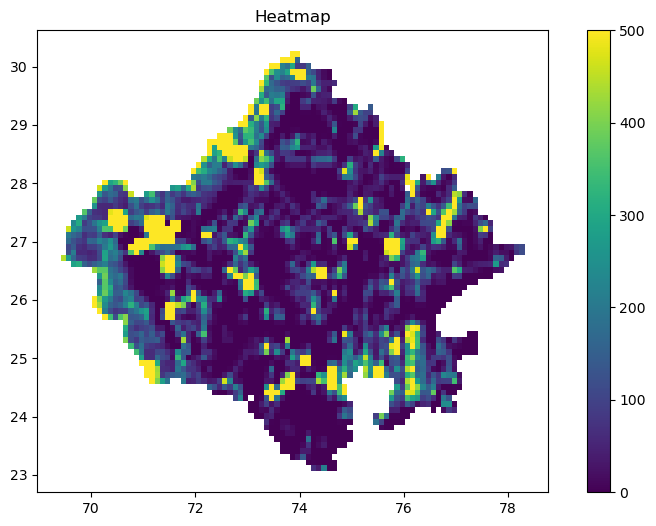

In [23]:


# Plot the 'heatmap' column of dataframe
fig, ax = plt.subplots(1, 1, figsize=(10, 6))
cax = cell_df.plot(column='heatmap', ax=ax, vmin=0, vmax=500, legend=True)

# Set a title
ax.set_title('Heatmap')

plt.show()


In [19]:
cell_df.crs = "EPSG:4326"

# convert CRS to EPSG:7755 (units in meters)
cell_df_meters = cell_df.to_crs(epsg=7755)

# filter to get only cells with high-resolution imagery
high_res_cells = cell_df_meters[cell_df_meters['heatmap'] > 0]

# Calculate area of each high-res cell in sq. km. and sum
total_area_sqkm = high_res_cells.geometry.area.sum() / 10**6

print(f"Total unique area with high-res imagery: {total_area_sqkm} square kilometers")


Total unique area with high-res imagery: 253585.6713761856 square kilometers


In [21]:
len(high_res_cells)

2386

In [16]:
len(cell_df)

3330